# CINEMA Asset Generator


In [3]:
import pandas as pd
import os

# --- CONFIGURATION ---
def generate_asset(input_csv, output_asset, glb_filename, identifier):
    # Load data
    df = pd.read_csv(input_csv)

    # Downsample df; no need to overload the rendering pipeline.
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    df = df.dropna(subset=['Time']) # Drop rows where Time might be null to avoid Index errors
    df.set_index('Time', inplace=True)
    df = df.resample('2 min').mean()

    df= df.reset_index()
    # Ensure Time is in the right format: 2030-07-04T00:00:00.00Z
    df['Time'] = pd.to_datetime(df['Time']).dt.strftime('%Y-%m-%dT%H:%M:%S.00Z')

    # Reduce number of keyframes to something more manageable
    df = df.tail(5000)

    # Get Start and End times for the TimeFrameInterval
    start_time = df['Time'].iloc[0]
    end_time = df['Time'].iloc[-1]

    # Start building the Lua string
    lua = []
    lua.append('local sun = asset.require("scene/solarsystem/sun/transforms")')
    lua.append('local earthTransforms = asset.require("scene/solarsystem/planets/earth/earth")\n')

    # 1. Keyframes Table
    lua.append('-- 1. Keyframes')
    lua.append('local myKeyframes = {')
    for _, row in df.iterrows():
        # Scale km to meters
        x, y, z = row['x_J2000']*1000, row['y_J2000']*1000, row['z_J2000']*1000
        line = f'    ["{row["Time"]}"] = {{ Type = "StaticTranslation", Position = {{ {x:.2f}, {y:.2f}, {z:.2f} }} }},'
        lua.append(line)
    lua.append('}\n')

    # 2. Position Node
    lua.append('-- 2. Position Node')
    lua.append(f'local satellitePosition = {{')
    lua.append(f'    Identifier = "{identifier}_Pos",')
    lua.append(f'    Parent = "Earth",')
    lua.append(f'    TimeFrame = {{ Type = "TimeFrameInterval", Start = "{start_time}", End = "{end_time}" }},')
    lua.append(f'    Transform = {{ Translation = {{ Type = "TimelineTranslation", Keyframes = myKeyframes }} }},')
    lua.append(f'    GUI = {{ Name = "{identifier} Position", Path = "/CINEMA/Positions" }}')
    lua.append(f'}}\n')

    # 3. Model Node
    lua.append('-- 3. Renderable Model')
    lua.append(f'local satelliteModel = {{')
    lua.append(f'    Identifier = "{identifier}_Model",')
    lua.append(f'    Parent = "{identifier}_Pos",')
    lua.append(f'    Transform = {{ Scale = {{ Type = "StaticScale", Scale = 1000.0 }} }},')
    lua.append(f'    Renderable = {{')
    lua.append(f'        Type = "RenderableModel",')
    lua.append(f'        GeometryFile = asset.resource("{glb_filename}"),')
    lua.append(f'        BoundingSphere = 100.0,')
    lua.append(f'        LightSources = {{')
    lua.append(f'            sun.LightSource,')
    lua.append(f'            {{ Identifier = "{identifier}_CamLight", Type = "CameraLightSource", Intensity = 0.5 }}')
    lua.append(f'        }}')
    lua.append(f'    }},')
    lua.append(f'    GUI = {{ Name = "{identifier} Model", Path = "/CINEMA/Models" }}')
    lua.append(f'}}\n')

    # 4. Trail Node
    lua.append('-- 4. Trail')
    lua.append(f'local satelliteTrail = {{')
    lua.append(f'    Identifier = "{identifier}_Trail",')
    lua.append(f'    Parent = "Earth",')
    lua.append(f'    Renderable = {{')
    lua.append(f'        Type = "RenderableTrailTrajectory",')
    lua.append(f'        Enabled = true,')
    lua.append(f'        Translation = {{ Type = "TimelineTranslation", Keyframes = myKeyframes }},')
    lua.append(f'        Color = {{ {color_str} }},')
    lua.append(f'        StartTime = "{start_time}",')
    lua.append(f'        EndTime = "{end_time}",')
    lua.append(f'        SampleInterval = 10')
    lua.append(f'    }},')
    lua.append(f'    GUI = {{ Name = "{identifier} Trail", Path = "/CINEMA/Trails" }}')
    lua.append(f'}}\n')

    # 5. Initialization logic
    lua.append('asset.onInitialize(function()')
    lua.append(f'    openspace.addSceneGraphNode(satellitePosition)')
    lua.append(f'    openspace.addSceneGraphNode(satelliteModel)')
    lua.append(f'    openspace.addSceneGraphNode(satelliteTrail)')
    lua.append('end)\n')

    lua.append('asset.onDeinitialize(function()')
    lua.append(f'    openspace.removeSceneGraphNode(satelliteTrail)')
    lua.append(f'    openspace.removeSceneGraphNode(satelliteModel)')
    lua.append(f'    openspace.removeSceneGraphNode(satellitePosition)')
    lua.append('end)')

    # Write to file
    with open(output_asset, 'w') as f:
        f.write("\n".join(lua))
    print(f"Successfully created {output_asset}")

#if __name__ == "__main__":
#    generate_asset()

CSV Columns: ['Time', 'x_GSM', 'y_GSM', 'z_GSM', 'vx_GSM', 'vy_GSM', 'vz_GSM', 'x_SM', 'y_SM', 'z_SM', 'vx_SM', 'vy_SM', 'vz_SM', 'x_J2000', 'y_J2000', 'z_J2000', 'vx_J2000', 'vy_J2000', 'vz_J2000', 'inShadow', 'sma_km', 'mean_alt_km', 'inc_deg', 'raan_deg', 'ltan_hr']
Time span: 2030-07-04 00:00:00+00:00 -> 2032-08-22 00:00:00+00:00 (561601 rows)


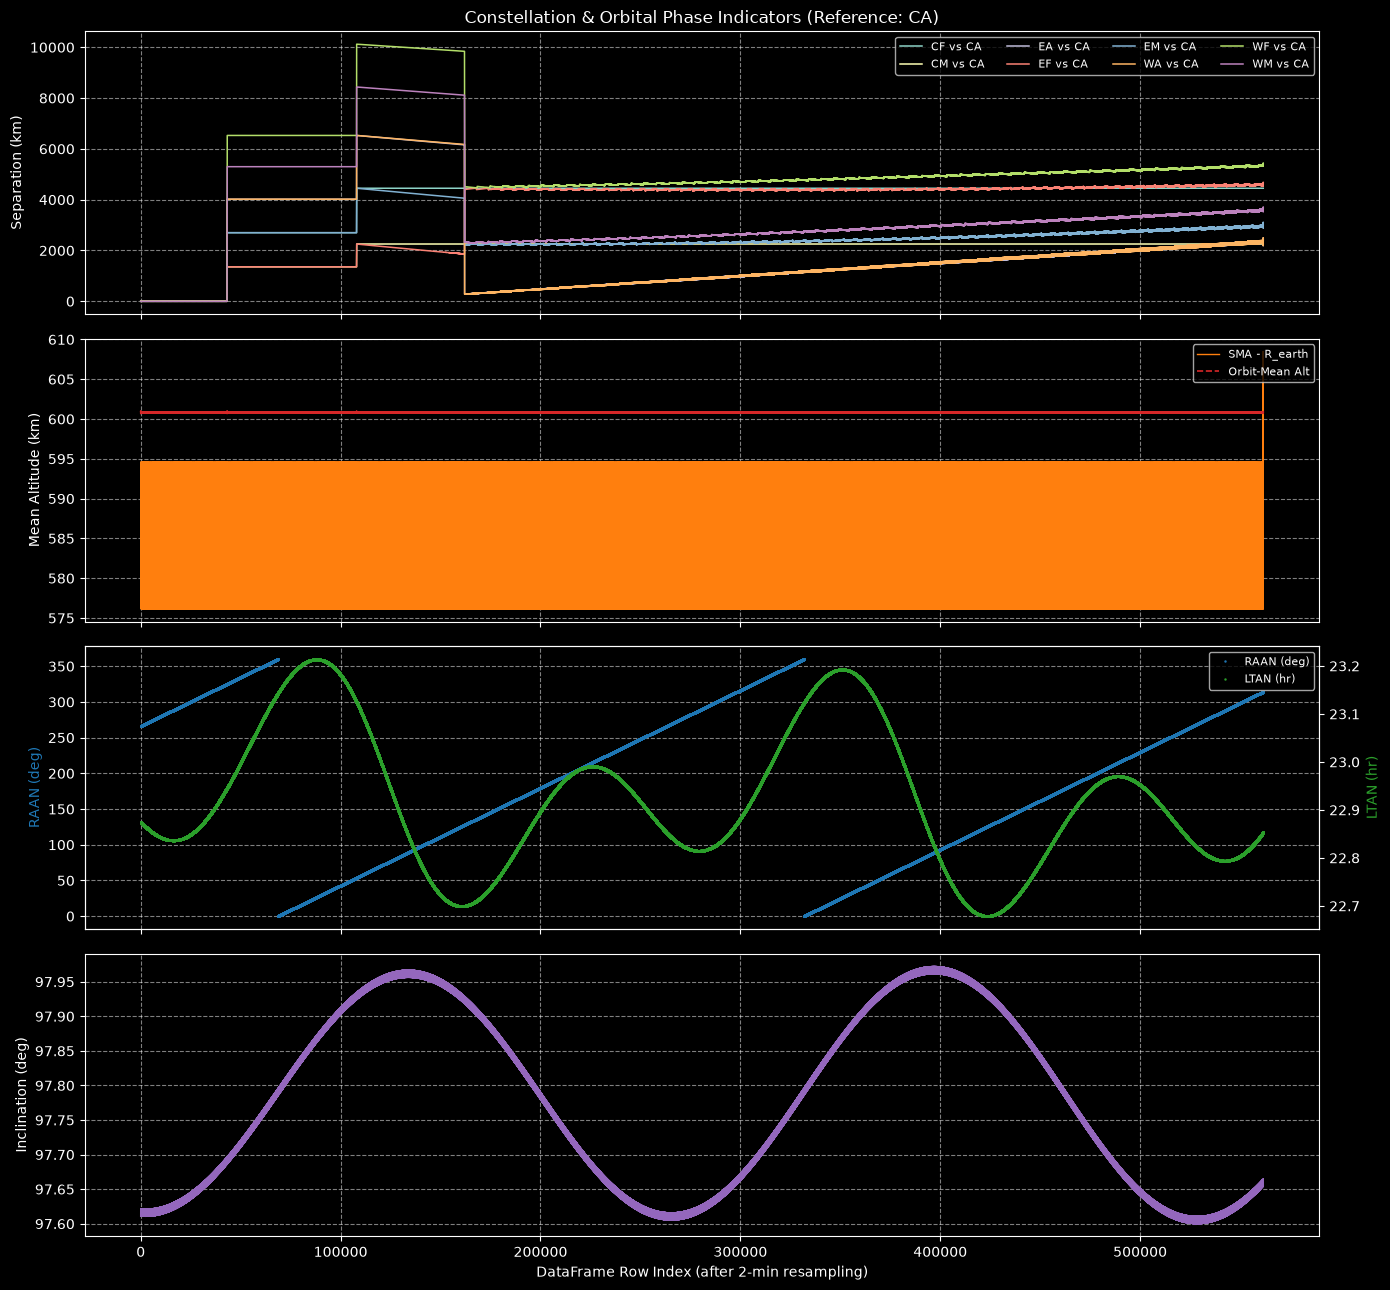

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def load_and_compute_elements(input_csv, resample_rule='2 min'):
    # Load and resample identically to generate_asset() so row indices match 1:1
    df = pd.read_csv(input_csv)
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce', utc=True)
    df = df.dropna(subset=['Time']).sort_values('Time')
    df = df.set_index('Time').resample(resample_rule).mean().reset_index()

    r = df[['x_J2000', 'y_J2000', 'z_J2000']].to_numpy()
    r_norm = np.linalg.norm(r, axis=1)

    # Use velocity columns if present; otherwise 4th-order finite difference
    if {'vx_J2000', 'vy_J2000', 'vz_J2000'}.issubset(df.columns):
        v = df[['vx_J2000', 'vy_J2000', 'vz_J2000']].to_numpy()
    else:
        dt = df['Time'].diff().dt.total_seconds().median()
        v = np.zeros_like(r)
        v[2:-2] = (-r[4:] + 8*r[3:-1] - 8*r[1:-3] + r[:-4]) / (12.0 * dt)
        v[:2], v[-2:] = v[2], v[-3]

    v_norm = np.linalg.norm(v, axis=1)
    mu = 398600.4418  # Earth gravitational parameter (km^3/s^2)

    # Semi-major axis (km) and orbit-averaged altitude (km)
    df['sma_km'] = 1.0 / (2.0 / r_norm - (v_norm**2) / mu)
    df['mean_alt_km'] = pd.Series(r_norm - 6378.137).rolling(50, center=True, min_periods=1).mean()

    # Angular momentum h = r x v -> Inclination & RAAN
    h = np.cross(r, v)
    h_norm = np.linalg.norm(h, axis=1)
    df['inc_deg'] = np.degrees(np.arccos(np.clip(h[:, 2] / h_norm, -1.0, 1.0)))
    raan_rad = np.mod(np.arctan2(h[:, 0], -h[:, 1]), 2 * np.pi)
    df['raan_deg'] = np.degrees(raan_rad)

    # Local Time of Ascending Node (LTAN, hours)
    jd = (df['Time'] - pd.Timestamp('1970-01-01', tz='UTC')) / pd.Timedelta(days=1) + 2440587.5
    d = jd - 2451545.0
    L = np.radians((280.460 + 0.9856474 * d) % 360.0)
    g = np.radians((357.528 + 0.9856003 * d) % 360.0)
    lam_sun = L + np.radians(1.915) * np.sin(g) + np.radians(0.020) * np.sin(2 * g)
    eps = np.radians(23.439 - 0.0000004 * d)
    ra_sun = np.arctan2(np.cos(eps) * np.sin(lam_sun), np.cos(lam_sun))
    df['ltan_hr'] = (12.0 + np.degrees(raan_rad - ra_sun) / 15.0) % 24.0

    return df

# --- LOAD ALL SATELLITES IN ID_list ---
dfs = {}
for sat_id in ID_list:
    path = f'2hr/2hr/cartesian_elems_umbra_flag_{sat_id}_20260306115024.txt'
    dfs[sat_id] = load_and_compute_elements(path, resample_rule='2 min')

ref_id = ID_list[0]
ref_df = dfs[ref_id]
print("CSV Columns:", list(ref_df.columns))
print(f"Time span: {ref_df['Time'].iloc[0]} -> {ref_df['Time'].iloc[-1]} ({len(ref_df)} rows)")

# --- PLOT SLOWLY VARYING PARAMETERS VS. DATAFRAME ROW INDEX ---
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)

# 1. Constellation Separation from reference satellite (orbit-smoothed)
if len(ID_list) > 1:
    ref_xyz = ref_df[['x_J2000', 'y_J2000', 'z_J2000']].to_numpy()
    for sat_id in ID_list[1:]:
        n = min(len(ref_df), len(dfs[sat_id]))
        dist = np.linalg.norm(dfs[sat_id][['x_J2000', 'y_J2000', 'z_J2000']].to_numpy()[:n] - ref_xyz[:n], axis=1)
        dist_smooth = pd.Series(dist).rolling(50, center=True, min_periods=1).mean()
        axes[0].plot(np.arange(n), dist_smooth, linewidth=1.1, label=f'{sat_id} vs {ref_id}')
    axes[0].set_ylabel('Separation (km)')
    axes[0].set_title(f'Constellation & Orbital Phase Indicators (Reference: {ref_id})')
    axes[0].legend(loc='upper right', ncol=4, fontsize=8)
else:
    axes[0].plot(ref_df.index, ref_df['inc_deg'], color='tab:purple')
    axes[0].set_ylabel('Inclination (deg)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Semi-major axis & orbit-averaged altitude (catches phasing maneuvers / drag decay)
axes[1].plot(ref_df.index, ref_df['sma_km'] - 6378.137, linewidth=1.0, color='tab:orange', label='SMA - R_earth')
axes[1].plot(ref_df.index, ref_df['mean_alt_km'], linewidth=1.2, color='tab:red', linestyle='--', label='Orbit-Mean Alt')
axes[1].set_ylabel('Mean Altitude (km)')
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. RAAN & LTAN (catches plane precession / magnetotail vs. dayside seasons)
ax3_twin = axes[2].twinx()
l1 = axes[2].plot(ref_df.index, ref_df['raan_deg'], '.', markersize=1.5, color='tab:blue', label='RAAN (deg)')
l2 = ax3_twin.plot(ref_df.index, ref_df['ltan_hr'], '.', markersize=1.5, color='tab:green', label='LTAN (hr)')
axes[2].set_ylabel('RAAN (deg)', color='tab:blue')
ax3_twin.set_ylabel('LTAN (hr)', color='tab:green')
axes[2].legend(l1 + l2, ['RAAN (deg)', 'LTAN (hr)'], loc='upper right', fontsize=8)
axes[2].grid(True, linestyle='--', alpha=0.5)

# 4. Umbra / Eclipse Fraction (if column exists) or Inclination
umbra_cols = [c for c in ref_df.columns if 'umbra' in c.lower() or 'eclipse' in c.lower()]
if umbra_cols:
    u_col = umbra_cols[0]
    u_smooth = ref_df[u_col].rolling(50, center=True, min_periods=1).mean()
    axes[3].plot(ref_df.index, u_smooth, linewidth=1.1, color='tab:cyan')
    axes[3].set_ylabel(f'Orbit-Mean {u_col}')
else:
    axes[3].plot(ref_df.index, ref_df['inc_deg'], linewidth=1.1, color='tab:purple')
    axes[3].set_ylabel('Inclination (deg)')
axes[3].set_xlabel('DataFrame Row Index (after 2-min resampling)')
axes[3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [4]:
# --- CONFIGURATION ---

ID_list = ["CA", "CF", "CM", "EA", "EF", "EM", "WA", "WF", "WM"]
import matplotlib.pyplot as plt
cmap = plt.get_cmap('hsv').resampled(10)


# for i in range(10):
#     color = cmap(i) # Access color directly by index
#     color_str = str(color[0]) + "," + str(color[1]) + "," + str(color[2])
#     print(color_str)


for i in range(len(ID_list)):
    ID = ID_list[i]
    color = cmap(i)
    color_str = str(color[0]) + "," + str(color[1]) + "," + str(color[2])
    print(f"color_str: {color_str}")
    IDENTIFIER = ID
    INPUT_CSV = '2hr/2hr/cartesian_elems_umbra_flag_' + ID + '_20260306115024.txt'  # Your original file name
    OUTPUT_ASSET = 'CINEMA_' + ID + '.asset'
    GLB_FILENAME = 'sat.glb'               # Must match your .glb file name
    generate_asset(INPUT_CSV, OUTPUT_ASSET, GLB_FILENAME, IDENTIFIER)



color_str: 1.0,0.0,0.0
Successfully created CINEMA_CA.asset
color_str: 1.0,0.6562506562506562,0.0
Successfully created CINEMA_CF.asset
color_str: 0.6874986874986876,1.0,0.0
Successfully created CINEMA_CM.asset
color_str: 0.031249343749343756,1.0,1.31250131249048e-06
Successfully created CINEMA_EA.asset
color_str: 0.0,1.0,0.6249990812548694
Successfully created CINEMA_EF.asset
color_str: 0.0,0.718752625002625,1.0
Successfully created CINEMA_EM.asset
color_str: 0.0,0.062501968751969,1.0
Successfully created CINEMA_WA.asset
color_str: 0.5937486874986869,0.0,1.0
Successfully created CINEMA_WF.asset
color_str: 1.0,0.0,0.750000656250656
Successfully created CINEMA_WM.asset


In [10]:
import pandas as pd
import numpy as np

def generate_asset(input_csv, output_asset, glb_filename, identifier, color_str,
                   row_start=None, row_end=None, max_keyframes=5000):
    # Load and resample identically to the diagnostic plot so row indices match 1:1
    df = pd.read_csv(input_csv)
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    df = df.dropna(subset=['Time']).sort_values('Time')
    df = df.set_index('Time').resample('2 min').mean().reset_index()

    # Slice to the requested orbital phase
    df = df.iloc[row_start:row_end].copy()

    # Subsample evenly across the entire phase rather than taking .tail(5000)
    if len(df) > max_keyframes:
        step = int(np.ceil(len(df) / max_keyframes))
        df = df.iloc[::step].copy()

    # Format timestamps for OpenSpace: YYYY-MM-DDTHH:MM:SS.00Z
    df['Time'] = df['Time'].dt.strftime('%Y-%m-%dT%H:%M:%S.00Z')
    start_time = df['Time'].iloc[0]
    end_time = df['Time'].iloc[-1]

    lua = [
        'local sun = asset.require("scene/solarsystem/sun/transforms")',
        'local earthTransforms = asset.require("scene/solarsystem/planets/earth/earth")\n',
        '-- 1. Keyframes',
        'local myKeyframes = {'
    ]

    for _, row in df.iterrows():
        x, y, z = row['x_J2000'] * 1000, row['y_J2000'] * 1000, row['z_J2000'] * 1000
        lua.append(f'    ["{row["Time"]}"] = {{ Type = "StaticTranslation", Position = {{ {x:.2f}, {y:.2f}, {z:.2f} }} }},')
    lua.append('}\n')

    lua.extend([
        '-- 2. Position Node',
        'local satellitePosition = {',
        f'    Identifier = "{identifier}_Pos",',
        '    Parent = "Earth",',
        f'    TimeFrame = {{ Type = "TimeFrameInterval", Start = "{start_time}", End = "{end_time}" }},',
        '    Transform = { Translation = { Type = "TimelineTranslation", Keyframes = myKeyframes } },',
        f'    GUI = {{ Name = "{identifier} Position", Path = "/CINEMA/Positions" }}',
        '}\n',
        '-- 3. Renderable Model',
        'local satelliteModel = {',
        f'    Identifier = "{identifier}_Model",',
        f'    Parent = "{identifier}_Pos",',
        '    Transform = { Scale = { Type = "StaticScale", Scale = 1000.0 } },',
        '    Renderable = {',
        '        Type = "RenderableModel",',
        f'        GeometryFile = asset.resource("{glb_filename}"),',
        '        BoundingSphere = 100.0,',
        '        LightSources = {',
        '            sun.LightSource,',
        f'            {{ Identifier = "{identifier}_CamLight", Type = "CameraLightSource", Intensity = 0.5 }}',
        '        }',
        '    },',
        f'    GUI = {{ Name = "{identifier} Model", Path = "/CINEMA/Models" }}',
        '}\n',
        '-- 4. Trail',
        'local satelliteTrail = {',
        f'    Identifier = "{identifier}_Trail",',
        '    Parent = "Earth",',
        '    Renderable = {',
        '        Type = "RenderableTrailTrajectory",',
        '        Enabled = true,',
        '        Translation = { Type = "TimelineTranslation", Keyframes = myKeyframes },',
        f'        Color = {{ {color_str} }},',
        f'        StartTime = "{start_time}",',
        f'        EndTime = "{end_time}",',
        '        SampleInterval = 600',
        '    },',
        f'    GUI = {{ Name = "{identifier} Trail", Path = "/CINEMA/Trails" }}',
        '}\n',
        'asset.onInitialize(function()',
        '    openspace.addSceneGraphNode(satellitePosition)',
        '    openspace.addSceneGraphNode(satelliteModel)',
        '    openspace.addSceneGraphNode(satelliteTrail)',
        'end)\n',
        'asset.onDeinitialize(function()',
        '    openspace.removeSceneGraphNode(satelliteTrail)',
        '    openspace.removeSceneGraphNode(satelliteModel)',
        '    openspace.removeSceneGraphNode(satellitePosition)',
        'end)'
    ])

    with open(output_asset, 'w') as f:
        f.write("\n".join(lua))
    print(f"Created {output_asset} ({len(df)} keyframes: {start_time} -> {end_time})")

# --- GENERATE ASSETS PER PHASE ---
# Replace these approximate indices with the exact output from step 1
phases = {
    "Phase1": (43000, 108000),
    "Phase2": (108000, 161000),
    "Phase3": (161000, None),
}

for phase_name, (start_idx, end_idx) in phases.items():
    for i, sat_id in enumerate(ID_list):
        color = cmap(i)
        color_str = f"{color[0]},{color[1]},{color[2]}"
        input_csv = f'2hr/2hr/cartesian_elems_umbra_flag_{sat_id}_20260306115024.txt'
        output_asset = f'CINEMA_{sat_id}_{phase_name}.asset'
        generate_asset(
            input_csv, output_asset, 'sat.glb',
            identifier=f"{sat_id}_{phase_name}",
            color_str=color_str,
            row_start=start_idx,
            row_end=end_idx
        )

usage: ipykernel_launcher.py [-h] [-o OUTPUT] [--no-retired] [--verify-ssl]
ipykernel_launcher.py: error: unrecognized arguments: -f C:\Users\kvc2\AppData\Local\Temp\kernel-05210e0a-3327-4170-adef-3c1cf5df4d602941737382004512363\connection.json --IPCompleter.use_jedi=False --IPKernelApp.log_level=INFO


SystemExit: 2

C:\Users\kvc2\AppData\Roaming\Python\Python312\site-packages\IPython\core\interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [5]:
# from harkness.create_ply import create_ply
# df = pd.read_csv(INPUT_CSV)

# # Downsample df; no need to overload the rendering pipeline.
# df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
# df = df.dropna(subset=['Time']) # Drop rows where Time might be null to avoid Index errors
# df.set_index('Time', inplace=True)
# df = df.resample('120T').mean()

# df= df.reset_index()
# # Ensure Time is in the right format: 2030-07-04T00:00:00.00Z
# df['Time'] = pd.to_datetime(df['Time']).dt.strftime('%Y-%m-%dT%H:%M:%S.00Z')
# # Create PLY file
# filename = 'example.ply'
# # create_ply(df, filename, C='C', is_verbose=True)
# create_ply(df, filename, C='Time', X='x_J2000', Y='y_J2000', Z='z_J2000', cmap='viridis', is_verbose=False)
# # px.scatter_3d(df.x_J2000, df.y_J2000, df.z_J2000)